# Machine-Learning–Based Early Detection of Life-Threatening Cardiac Arrhythmias
**MSDS 545 – Introduction to Computational Software Engineering · Chelsea Narcisse · Abrea Penn . Orlando Pender . Fall 2026**

This notebook is the machine-learning part of the project: data cleaning, EDA, **feature
engineering**, model training, evaluation, and saving the models (`.pkl`) that the FastAPI backend
serves to the Streamlit dashboard.

| Part | Data (Kaggle) | Model |
|---|---|---|
| 1–9 | *ECG Arrhythmia Classification* (Sakib et al.): 34 measured features per beat, `MIT-BIH Arrhythmia Database.csv` | 5-class AAMI beat classifier (main model) |
| 10 | Same dataset: `INCART`, `MIT-BIH Supraventricular`, `Sudden Cardiac Death Holter` | External validation |
| 11–12 | *ECG Heartbeat Categorization* (Kachuee et al.): 187-sample waveforms | Waveform arrhythmia model + myocardial-infarction detector |
| 13 | – | Save models for the API |

AAMI classes: **N** normal · **SVEB** supraventricular ectopic · **VEB** ventricular ectopic ·
**F** fusion · **Q** unclassifiable.

## 0. Setup
Install the libraries once (uncomment in Colab or a fresh environment), then set `DATA_DIR` to the
folder that holds the Kaggle CSV files.

In [ ]:
# !pip install pandas numpy scikit-learn matplotlib joblib
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---- Paths: change these to where your files are ----
DATA_DIR = Path("../data/raw")                 # Sakib feature CSVs (zip 2)
WAVE_DIR = DATA_DIR / "waveform"               # Kachuee waveform CSVs (zip 1)
MODEL_DIR = Path("../backend/models")          # where the API loads models from
MODEL_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
AAMI_CLASSES = ["N", "SVEB", "VEB", "F", "Q"]
TRAIN_CLASSES = ["N", "SVEB", "VEB", "F"]
CLASS_COLORS = {"N": "#2a78d6", "SVEB": "#eb6834", "VEB": "#1baf7a", "F": "#eda100", "Q": "#e87ba4"}
print("Data folder exists:", DATA_DIR.exists())

Data folder exists: False


In [ ]:
# === COLAB DATA FIX: run this right after the Setup cell ===
import shutil, zipfile
from pathlib import Path

BASE = Path("/content")
CSV_NAMES = {
    "MIT-BIH Arrhythmia Database.csv": "mitbih_features.csv",
    "INCART 2-lead Arrhythmia Database.csv": "incart_features.csv",
    "MIT-BIH Supraventricular Arrhythmia Database.csv": "svdb_features.csv",
    "Sudden Cardiac Death Holter Database.csv": "scdh_features.csv",
    "mitbih_train.csv": "waveform/mitbih_train.csv",
    "mitbih_test.csv": "waveform/mitbih_test.csv",
    "ptbdb_normal.csv": "waveform/ptbdb_normal.csv",
    "ptbdb_abnormal.csv": "waveform/ptbdb_abnormal.csv",
}
DATA_DIR = BASE / "data" / "raw"
WAVE_DIR = DATA_DIR / "waveform"
MODEL_DIR = BASE / "models"
for d in (WAVE_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Files in", BASE, ":", sorted(p.name for p in BASE.iterdir()))

# 1) CSVs inside any .zip anywhere under /content
for z in BASE.rglob("*.zip"):
    try:
        with zipfile.ZipFile(z) as zf:
            for member in zf.namelist():
                name = Path(member).name
                if name in CSV_NAMES and not (DATA_DIR / CSV_NAMES[name]).exists():
                    with zf.open(member) as src, open(DATA_DIR / CSV_NAMES[name], "wb") as dst:
                        shutil.copyfileobj(src, dst)
                    print(f"unzipped {name}  (from {z.name})")
    except zipfile.BadZipFile:
        print(f"!! {z.name} is not a valid zip (upload may be incomplete) - upload it again")

# 2) CSVs that were already unzipped / uploaded directly
for csv in BASE.rglob("*.csv"):
    if csv.name in CSV_NAMES and DATA_DIR not in csv.parents:
        target = DATA_DIR / CSV_NAMES[csv.name]
        if not target.exists():
            shutil.copy(csv, target)
            print(f"copied   {csv.name}")

missing = [orig for orig, new in CSV_NAMES.items() if not (DATA_DIR / new).exists()]
if missing:
    print("\nSTILL MISSING:", missing, "\n-> upload the Kaggle zip that contains these files")
else:
    print("\nAll 8 data files are ready in", DATA_DIR)

Files in /content : ['.config', 'INCART 2-lead Arrhythmia Database.csv', 'MIT-BIH Arrhythmia Database.csv', 'MIT-BIH Supraventricular Arrhythmia Database.csv', 'Sudden Cardiac Death Holter Database.csv', 'data', 'drive', 'mitbih_test.csv', 'mitbih_train.csv', 'models', 'ptbdb_abnormal.csv', 'ptbdb_normal.csv', 'sample_data']
copied   MIT-BIH Arrhythmia Database.csv
copied   INCART 2-lead Arrhythmia Database.csv

All 8 data files are ready in /content/data/raw


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load the MIT-BIH feature data
Each row is one heartbeat with 32 numeric features (16 per ECG lead, prefixed `0_` and `1_`),
the recording id (`record`, one per patient) and the beat label (`type`).

In [ ]:
df_raw = pd.read_csv(DATA_DIR / "mitbih_features.csv")   # "MIT-BIH Arrhythmia Database.csv"
print(df_raw.shape)
df_raw.head()

(100689, 34)


,record,type,0_pre-RR,0_post-RR,0_pPeak,0_tPeak,0_rPeak,0_sPeak,0_qPeak,0_qrs_interval,0_pq_interval,0_qt_interval,0_st_interval,0_qrs_morph0,0_qrs_morph1,0_qrs_morph2,0_qrs_morph3,0_qrs_morph4,1_pre-RR,1_post-RR,1_pPeak,1_tPeak,1_rPeak,1_sPeak,1_qPeak,1_qrs_interval,1_pq_interval,1_qt_interval,1_st_interval,1_qrs_morph0,1_qrs_morph1,1_qrs_morph2,1_qrs_morph3,1_qrs_morph4
0,101,N,76,313.0,0.074347,-0.160548,1.036401,-0.285662,-0.026824,41,18,66,7,-0.026824,-0.001236,0.016659,0.143241,0.996287,76,313.0,0.038310,0.025784,0.025930,0.025271,0.025930,2,18,22,2,0.025930,0.025930,0.025930,0.025436,0.025436
1,101,N,313,315.0,-0.052079,-0.264784,0.886597,-0.366298,-0.059710,21,4,33,8,-0.059710,0.104030,0.691891,0.805549,0.084069,313,315.0,0.014264,0.045458,0.032573,-0.104503,-0.042009,26,27,62,9,-0.042009,-0.029498,0.005012,0.030892,0.002986
2,101,N,315,321.0,-0.062151,-0.296983,0.991859,-0.410306,-0.065686,22,3,32,7,-0.065686,0.051459,0.630419,0.890794,0.091258,315,321.0,0.021311,0.008246,0.009528,0.008230,0.009528,3,8,12,1,0.009528,0.009528,0.008786,0.008786,0.008368
3,101,N,321,336.0,-0.063322,-0.281386,1.034903,-0.403880,-0.071750,22,4,33,7,-0.071750,0.059376,0.652814,0.948490,0.136602,321,336.0,-0.000665,-0.009725,-0.010203,-0.010203,-0.020536,6,9,16,1,-0.020536,-0.020257,-0.018965,-0.016968,-0.014555
4,101,N,336,344.0,-0.062915,1.046914,1.046408,1.046408,-0.074639,11,4,16,1,-0.074639,-0.054516,0.052823,0.296038,0.649990,336,344.0,0.024559,0.016925,0.016053,-0.099918,0.016053,16,5,31,10,0.016053,0.006742,0.002782,-0.007798,-0.051155


In [ ]:
LEADS = ["0", "1"]
PER_LEAD_FEATURES = ["pre-RR", "post-RR", "pPeak", "tPeak", "rPeak", "sPeak", "qPeak",
                     "qrs_interval", "pq_interval", "qt_interval", "st_interval",
                     "qrs_morph0", "qrs_morph1", "qrs_morph2", "qrs_morph3", "qrs_morph4"]
RAW_FEATURE_COLUMNS = [f"{lead}_{f}" for lead in LEADS for f in PER_LEAD_FEATURES]

print("Patients (records):", df_raw["record"].nunique())
print("Missing values:", int(df_raw.isna().sum().sum()))
print(df_raw["type"].value_counts())

Patients (records): 44
Missing values: 0
type
N       90083
VEB      7009
SVEB     2779
F         803
Q          15
Name: count, dtype: int64


## 2. Cleaning and EDA
### 2.1 Redundant columns
Some columns look alike, so we check whether any are exact copies of another.

In [ ]:
pairs = [("0_pre-RR", "1_pre-RR"), ("0_post-RR", "1_post-RR"),
         ("0_qPeak", "0_qrs_morph0"), ("1_qPeak", "1_qrs_morph0")]
for a, b in pairs:
    print(f"{a:12s} == {b:14s}: {(df_raw[a] == df_raw[b]).mean():.0%} of beats")

REDUNDANT_COLUMNS = ["1_pre-RR", "1_post-RR", "0_qrs_morph0", "1_qrs_morph0"]

0_pre-RR     == 1_pre-RR      : 100% of beats
0_post-RR    == 1_post-RR     : 100% of beats
0_qPeak      == 0_qrs_morph0  : 100% of beats
1_qPeak      == 1_qrs_morph0  : 100% of beats


All four pairs are identical in 100% of beats, so the duplicates are dropped before modeling.

### 2.2 Class imbalance and the Q class

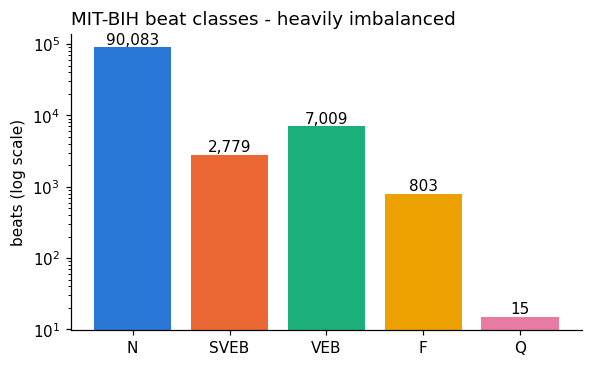

Normal beats: 89.5%


In [ ]:
counts = df_raw["type"].value_counts().reindex(AAMI_CLASSES)
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index])
ax.set_yscale("log"); ax.set_ylabel("beats (log scale)")
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values])
ax.set_title("MIT-BIH beat classes - heavily imbalanced", loc="left")
plt.show()
print(f"Normal beats: {counts['N'] / counts.sum():.1%}")

* 89.5% of beats are normal, so plain accuracy is misleading (always guessing "N" scores 89%).
  **Balanced accuracy** (mean recall over classes) is the main metric, and the models use class weights.
* **Q has only 15 beats** in the whole database: far too few to learn. It is excluded, as in most
  inter-patient studies.

In [ ]:
df = df_raw.dropna(subset=RAW_FEATURE_COLUMNS + ["type"])
df = df[(df["0_pre-RR"] > 0) & (df["0_post-RR"] > 0)]
df = df[df["type"].isin(TRAIN_CLASSES)].reset_index(drop=True)
print(f"{len(df_raw):,} beats -> {len(df):,} after cleaning")

100,689 beats -> 100,674 after cleaning


## 3. Feature engineering ★
Raw features are measured in **samples** (MIT-BIH is sampled at 360 Hz) and as **absolute**
amplitudes. A cardiologist instead judges each beat *relative to the patient's own rhythm*:

| Group | Features | Why |
|---|---|---|
| Unit conversion | `*_qrs_ms`, `*_qt_ms`, `pre_rr_ms` | Databases recorded at different Hz become comparable |
| Rhythm / prematurity | `rr_ratio`, `rr_norm_local`, `rr_norm_record`, `rr_diff_ms`, `heart_rate_bpm` | Ectopic beats arrive **early**, then a compensatory pause follows |
| Intervals | `qtc_bazett_ms`, `wide_qrs_flag` | Ventricular beats have a **wide** QRS (> 120 ms) |
| Morphology | QRS amplitude, R/S and T/R ratios, QRS energy and slope, cross-lead R difference | Beat shape |

`rr_norm_local` compares each beat with the mean of the **previous 10** beats only (causal), as a
real-time wearable would have to. This is the same code as `backend/cardio_ml/features.py`, so the
API engineers features exactly the same way.

In [ ]:
EPS = 1e-6
LOCAL_RR_WINDOW = 10
INTERVALS = ["qrs_interval", "pq_interval", "qt_interval", "st_interval"]

ENGINEERED_FEATURE_COLUMNS = [
    "pre_rr_ms", "post_rr_ms", "rr_ratio", "rr_diff_ms", "heart_rate_bpm",
    "local_rr_mean_ms", "rr_norm_local", "rr_norm_record", "post_rr_norm_local",
    *[f"{lead}_{iv.replace('_interval', '')}_ms" for lead in LEADS for iv in INTERVALS],
    "qtc_bazett_ms", "wide_qrs_flag",
    *[f"{lead}_{name}" for lead in LEADS for name in
      ("qrs_amplitude", "r_s_ratio", "t_r_ratio", "qrs_energy", "qrs_slope")],
    "lead_r_diff",
]
RAW_MODEL_COLUMNS = [c for c in RAW_FEATURE_COLUMNS if c not in REDUNDANT_COLUMNS]
MODEL_FEATURE_COLUMNS = RAW_MODEL_COLUMNS + ENGINEERED_FEATURE_COLUMNS


def samples_to_ms(samples, sampling_rate_hz):
    # Convert a duration measured in samples into milliseconds.
    return samples * (1000.0 / sampling_rate_hz)


def bazett_qtc(qt_ms, rr_ms):
    # Heart-rate-corrected QT interval: QTc = QT / sqrt(RR in seconds).
    rr_s = np.clip(rr_ms / 1000.0, 0.2, 3.0)
    return qt_ms / np.sqrt(rr_s)


def safe_ratio(num, den, clip=10.0):
    # Ratio that never divides by zero, clipped to +/- clip.
    den = den.where(den.abs() > EPS, np.sign(den).replace(0, 1) * EPS)
    return (num / den).clip(-clip, clip)


def local_rr_baseline(pre_rr_ms, groups, window=LOCAL_RR_WINDOW):
    # Causal rolling mean of the PREVIOUS `window` RR intervals, per patient.
    def _roll(s):
        return s.shift(1).rolling(window, min_periods=1).mean().fillna(s)
    if groups is None:
        return _roll(pre_rr_ms)
    return pre_rr_ms.groupby(groups, sort=False).transform(_roll)


def engineer_features(df, sampling_rate_hz=360, group_col="record"):
    raw = df[RAW_FEATURE_COLUMNS].astype(float).reset_index(drop=True)
    groups = df[group_col].astype(str).reset_index(drop=True) if group_col in df.columns else None
    out = pd.DataFrame(index=raw.index)

    # 1. Rhythm
    pre = samples_to_ms(raw["0_pre-RR"], sampling_rate_hz)
    post = samples_to_ms(raw["0_post-RR"], sampling_rate_hz)
    out["pre_rr_ms"], out["post_rr_ms"] = pre, post
    out["rr_ratio"] = safe_ratio(pre, post)                      # < 1 => premature beat
    out["rr_diff_ms"] = post - pre                               # > 0 => compensatory pause
    out["heart_rate_bpm"] = (60000.0 / pre.clip(lower=150)).clip(upper=400)
    local = local_rr_baseline(pre, groups)
    out["local_rr_mean_ms"] = local
    out["rr_norm_local"] = safe_ratio(pre, local)
    out["post_rr_norm_local"] = safe_ratio(post, local)
    record_median = (pd.Series(pre.median(), index=pre.index) if groups is None
                     else pre.groupby(groups, sort=False).transform("median"))
    out["rr_norm_record"] = safe_ratio(pre, record_median)

    # 2. Intervals
    for lead in LEADS:
        for iv in INTERVALS:
            out[f"{lead}_{iv.replace('_interval', '')}_ms"] = samples_to_ms(raw[f"{lead}_{iv}"], sampling_rate_hz)
    out["qtc_bazett_ms"] = bazett_qtc(out["0_qt_ms"], pre).clip(upper=2000)
    out["wide_qrs_flag"] = (out["0_qrs_ms"] > 120).astype(float)

    # 3. Morphology
    for lead in LEADS:
        r, s, t = raw[f"{lead}_rPeak"], raw[f"{lead}_sPeak"], raw[f"{lead}_tPeak"]
        morph = raw[[f"{lead}_qrs_morph{i}" for i in range(5)]]
        out[f"{lead}_qrs_amplitude"] = r - s
        out[f"{lead}_r_s_ratio"] = safe_ratio(r.abs(), s.abs())
        out[f"{lead}_t_r_ratio"] = safe_ratio(t, r)
        out[f"{lead}_qrs_energy"] = (morph ** 2).sum(axis=1)
        out[f"{lead}_qrs_slope"] = raw[f"{lead}_qrs_morph4"] - raw[f"{lead}_qrs_morph0"]
    out["lead_r_diff"] = raw["0_rPeak"] - raw["1_rPeak"]

    result = pd.concat([raw[RAW_MODEL_COLUMNS], out[ENGINEERED_FEATURE_COLUMNS]], axis=1)
    return result.replace([np.inf, -np.inf], np.nan).fillna(0.0)[MODEL_FEATURE_COLUMNS]


feats = engineer_features(df, sampling_rate_hz=360)
y = df["type"].astype(str).to_numpy()
print(f"{len(RAW_FEATURE_COLUMNS)} raw columns - {len(REDUNDANT_COLUMNS)} duplicates "
      f"+ {len(ENGINEERED_FEATURE_COLUMNS)} engineered = {feats.shape[1]} model features")
feats[ENGINEERED_FEATURE_COLUMNS[:9]].describe().T.round(2)

32 raw columns - 4 duplicates + 30 engineered = 58 model features


,count,mean,std,min,25%,50%,75%,max
pre_rr_ms,100674.0,776.15,227.50,30.56,638.89,741.67,900.00,5872.22
post_rr_ms,100674.0,773.86,225.34,16.67,638.89,738.89,894.44,5872.22
rr_ratio,100674.0,1.05,0.41,0.03,0.97,1.00,1.05,10.00
rr_diff_ms,100674.0,-2.28,225.51,-4680.56,-33.33,-2.78,25.00,5108.33
heart_rate_bpm,100674.0,84.43,29.72,10.22,66.67,80.90,93.91,400.00
local_rr_mean_ms,100674.0,775.60,176.29,77.78,650.83,735.83,884.17,1958.61
rr_norm_local,100674.0,1.01,0.22,0.03,0.96,1.00,1.04,10.00
rr_norm_record,100674.0,1.00,0.22,0.03,0.95,1.00,1.05,7.95
post_rr_norm_local,100674.0,1.00,0.23,0.02,0.96,1.00,1.04,10.00


### 3.1 Do the engineered features separate the classes?

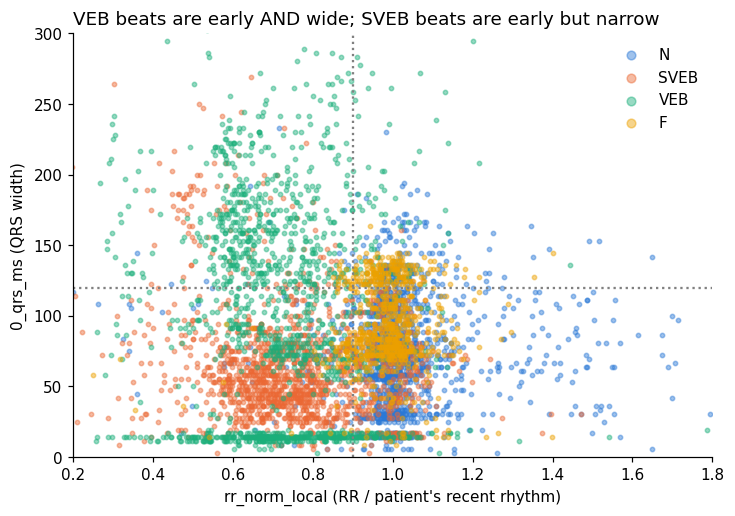

In [ ]:
both = pd.concat([df[["type"]], feats], axis=1)
idx = [i for _, g in both.groupby("type") for i in g.sample(min(len(g), 1500), random_state=0).index]
sample = both.loc[idx]                                   # up to 1,500 beats per class
fig, ax = plt.subplots(figsize=(7.5, 5))
for c in TRAIN_CLASSES:
    s = sample[sample["type"] == c]
    ax.scatter(s["rr_norm_local"], s["0_qrs_ms"], s=8, alpha=0.45, color=CLASS_COLORS[c], label=c)
ax.axvline(0.9, ls=":", color="gray"); ax.axhline(120, ls=":", color="gray")
ax.set_xlim(0.2, 1.8); ax.set_ylim(0, 300)
ax.set_xlabel("rr_norm_local (RR / patient's recent rhythm)"); ax.set_ylabel("0_qrs_ms (QRS width)")
ax.set_title("VEB beats are early AND wide; SVEB beats are early but narrow", loc="left")
ax.legend(markerscale=2, frameon=False)
plt.show()

## 4. Inter-patient train/test split
Beats from the same patient look alike, so a random split lets the model "recognise" patients
and inflates the score. We use the standard **inter-patient split of de Chazal et al. (2004)**:
train on 22 patients (DS1), test on 22 **different** patients (DS2).

In [ ]:
DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122,
       124, 201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210,
       212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234]

is_ds1 = df["record"].isin(DS1).to_numpy()
is_ds2 = df["record"].isin(DS2).to_numpy()
X_tr, X_te, y_tr, y_te = feats[is_ds1], feats[is_ds2], y[is_ds1], y[is_ds2]
print(f"Train (DS1): {len(X_tr):,} beats | Test (DS2): {len(X_te):,} beats")
pd.DataFrame({"train": pd.Series(y_tr).value_counts(), "test": pd.Series(y_te).value_counts()}).reindex(TRAIN_CLASSES)

Train (DS1): 50,991 beats | Test (DS2): 49,683 beats


,train,test
N,45845,44238
SVEB,943,1836
VEB,3788,3221
F,415,388


## 5. Evaluation helpers and a rule-based baseline
The rule-based classifier is the transparent baseline and also the API's fallback when no ML
model is loaded:
1. wide QRS (> 120 ms) **and** RR < 90% of the local rhythm → VEB
2. narrow QRS **and** RR < 85% of the local rhythm → SVEB
3. otherwise → N

In [ ]:
def evaluate(y_true, y_pred, proba=None, classes=AAMI_CLASSES, present=TRAIN_CLASSES, normal="N"):
    report = classification_report(y_true, y_pred, labels=classes, output_dict=True, zero_division=0)
    out = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=present, average="macro", zero_division=0),
        "per_class": {c: {k: report[c][k] for k in ("precision", "recall", "f1-score", "support")} for c in classes},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=classes).tolist(),
        "labels": classes,
    }
    if proba is not None:   # AUC of "abnormal vs normal" using the risk score 1 - P(normal)
        out["abnormal_auc"] = roc_auc_score((np.asarray(y_true) != normal).astype(int),
                                            1 - proba[:, classes.index(normal)])
    return out


def proba_aligned(est, X, classes=AAMI_CLASSES):
    # predict_proba re-ordered to `classes` (classes the model never saw get 0).
    p = est.predict_proba(X)
    out = np.zeros((len(X), len(classes)))
    for j, c in enumerate(est.classes_):
        out[:, classes.index(str(c))] = p[:, j]
    return out


def fit_predict(est, X_tr, y_tr, X_te):
    est = clone(est).fit(X_tr, y_tr)
    proba = proba_aligned(est, X_te)
    return est, np.array(AAMI_CLASSES)[proba.argmax(axis=1)], proba


class RuleBasedClassifier:
    classes_ = np.array(AAMI_CLASSES)

    def predict(self, f):
        wide = f["0_qrs_ms"] > 120
        return np.where(wide & (f["rr_norm_local"] < 0.90), "VEB",
                        np.where(~wide & (f["rr_norm_local"] < 0.85), "SVEB", "N"))

    def predict_proba(self, f):
        labels = self.predict(f)
        proba = np.full((len(labels), 5), 0.0625)
        for i, c in enumerate(AAMI_CLASSES):
            proba[labels == c, i] = 0.75
        return proba


results = {}
rules = RuleBasedClassifier()
results["rules"] = evaluate(y_te, rules.predict(X_te), rules.predict_proba(X_te))
print(f"Rule-based baseline: balanced accuracy = {results['rules']['balanced_accuracy']:.3f}")

Rule-based baseline: balanced accuracy = 0.500


## 6. Train the machine-learning models
Three scikit-learn models, all with class weighting for the imbalance. (XGBoost can be added the
same way if it is installed.)

In [ ]:
MODELS = {
    "logistic": ("Logistic Regression", Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5))])),
    "rf": ("Random Forest", Pipeline([
        ("clf", RandomForestClassifier(n_estimators=150, max_depth=18, min_samples_leaf=3,
                                       class_weight="balanced_subsample", n_jobs=-1,
                                       random_state=RANDOM_STATE))])),
    "hgb": ("Gradient Boosting (HistGB)", Pipeline([
        ("clf", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, max_leaf_nodes=31,
                                               l2_regularization=1.0, class_weight="balanced",
                                               random_state=RANDOM_STATE))])),
}

fitted = {}
for name, (display_name, est) in MODELS.items():
    t = time.time()
    model, pred, proba = fit_predict(est, X_tr, y_tr, X_te)
    fitted[name] = model
    results[name] = evaluate(y_te, pred, proba)
    print(f"{display_name:28s} trained in {time.time() - t:5.1f}s")

names = {"rules": "Rule-based triage", **{k: v[0] for k, v in MODELS.items()}}
summary = pd.DataFrame({names[n]: {
    "accuracy": r["accuracy"], "balanced_accuracy": r["balanced_accuracy"], "macro_f1": r["macro_f1"],
    "abnormal_auc": r["abnormal_auc"], **{f"recall_{c}": r["per_class"][c]["recall"] for c in TRAIN_CLASSES}}
    for n, r in results.items()}).T
summary.round(3)

Logistic Regression          trained in  13.5s
Random Forest                trained in  55.1s
Gradient Boosting (HistGB)   trained in   7.7s


,accuracy,balanced_accuracy,macro_f1,abnormal_auc,recall_N,recall_SVEB,recall_VEB,recall_F
Rule-based triage,0.890,0.500,0.438,0.855,0.947,0.781,0.271,0.000
Logistic Regression,0.725,0.527,0.458,0.894,0.738,0.225,0.886,0.258
Random Forest,0.934,0.513,0.513,0.919,0.979,0.073,0.913,0.088
Gradient Boosting (HistGB),0.843,0.725,0.508,0.904,0.864,0.179,0.937,0.920


Gradient boosting has the best **balanced accuracy on unseen patients** and catches more than
90% of ventricular (VEB) and fusion (F) beats, the ones linked to life-threatening rhythms. It is
the model the API serves by default.

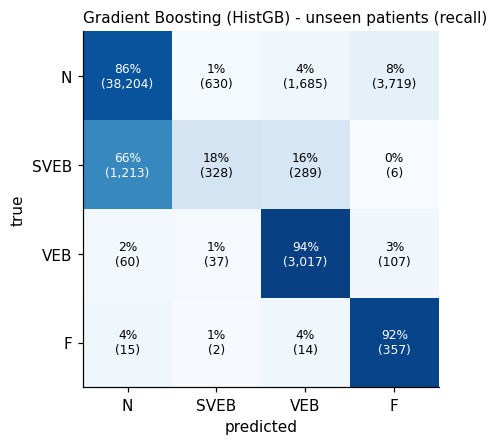

In [ ]:
best = max(MODELS, key=lambda n: results[n]["balanced_accuracy"])
cm = np.array(results[best]["confusion_matrix"])[:4, :4].astype(float)
norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{norm[i, j]:.0%}\n({int(cm[i, j]):,})", ha="center", va="center", fontsize=8,
                color="white" if norm[i, j] > 0.55 else "black")
ax.set_xticks(range(4), TRAIN_CLASSES); ax.set_yticks(range(4), TRAIN_CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"{names[best]} - unseen patients (recall)", loc="left", fontsize=10)
plt.show()

## 7. Feature-engineering ablation
Same models, trained on the raw columns only, to measure what the engineered features add.

In [ ]:
# Self-contained: trains each model twice (raw columns only vs raw + engineered),
# so it works even if earlier cells were re-run out of order.
ablation = {}
for name in ("logistic", "hgb"):
    _, pred_raw, _ = fit_predict(MODELS[name][1], X_tr[RAW_MODEL_COLUMNS], y_tr, X_te[RAW_MODEL_COLUMNS])
    _, pred_all, _ = fit_predict(MODELS[name][1], X_tr, y_tr, X_te)
    ablation[MODELS[name][0]] = {"raw features only": balanced_accuracy_score(y_te, pred_raw),
                                 "raw + engineered": balanced_accuracy_score(y_te, pred_all)}
abl = pd.DataFrame(ablation).T
abl["gain (points)"] = 100 * (abl["raw + engineered"] - abl["raw features only"])
abl.round(3)

,raw features only,raw + engineered,gain (points)
Logistic Regression,0.704,0.527,-17.752
Gradient Boosting (HistGB),0.554,0.725,17.091


For gradient boosting the engineered features add about **+17 points** of balanced accuracy.
Logistic regression does not benefit: the ratio features are non-linear and heavy-tailed, which
tree models handle far better than a linear model.

## 8. Why the evaluation design matters: random split vs inter-patient

In [ ]:
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(feats, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
_, pred_r, _ = fit_predict(MODELS["hgb"][1], Xr_tr, yr_tr, Xr_te)
pd.DataFrame({
    "Random split (same patients in train and test)": {"accuracy": accuracy_score(yr_te, pred_r),
                                                       "balanced_accuracy": balanced_accuracy_score(yr_te, pred_r)},
    "Inter-patient split (unseen patients)": {"accuracy": results["hgb"]["accuracy"],
                                              "balanced_accuracy": results["hgb"]["balanced_accuracy"]},
}).T.round(3)

The random split looks far better because the model has already seen beats from every test
patient. The inter-patient number is the honest estimate for a **new** wearer.

## 9. Feature importance (permutation importance on unseen patients)

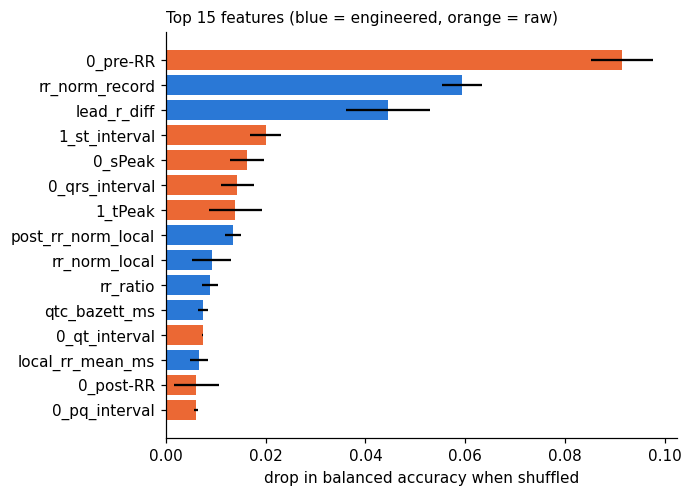

In [ ]:
Xs, _, ys, _ = train_test_split(X_te, y_te, train_size=6000, stratify=y_te, random_state=RANDOM_STATE)
imp = permutation_importance(fitted["hgb"], Xs, ys, n_repeats=3, random_state=RANDOM_STATE,
                             scoring="balanced_accuracy", n_jobs=-1)
importance = (pd.DataFrame({"feature": MODEL_FEATURE_COLUMNS, "importance": imp.importances_mean,
                            "std": imp.importances_std})
                .assign(engineered=lambda d: d["feature"].isin(ENGINEERED_FEATURE_COLUMNS))
                .sort_values("importance", ascending=False).head(15))
fig, ax = plt.subplots(figsize=(6, 4.8))
top = importance.iloc[::-1]
ax.barh(top["feature"], top["importance"], xerr=top["std"],
        color=np.where(top["engineered"], "#2a78d6", "#eb6834"))
ax.set_xlabel("drop in balanced accuracy when shuffled")
ax.set_title("Top 15 features (blue = engineered, orange = raw)", loc="left", fontsize=10)
plt.show()

## 10. External validation on other databases
The trained model is applied **unchanged** to three other databases in the same format. None of
their patients were seen in training. Each file is cleaned the same way and converted at its own
sampling rate.

In [ ]:
EXTERNAL = {
    "St Petersburg INCART": ("incart_features.csv", 257),
    "MIT-BIH Supraventricular": ("svdb_features.csv", 128),
    "Sudden Cardiac Death Holter": ("scdh_features.csv", 250),
}


def load_external(path):
    d = pd.read_csv(path, low_memory=False)
    n0 = len(d)
    d = d.dropna(subset=RAW_FEATURE_COLUMNS + ["type"])          # empty rows / beats missing a lead
    d = d[(d["0_pre-RR"] > 0) & (d["0_post-RR"] > 0)]
    d = d[d["type"].astype(str).isin(TRAIN_CLASSES)].reset_index(drop=True)
    return d, n0


ext_rows = []
for db, (fname, hz) in EXTERNAL.items():
    if not (DATA_DIR / fname).exists():
        print("skipping", db, "- file not found")
        continue
    ext, n0 = load_external(DATA_DIR / fname)
    y_ext = ext["type"].astype(str).to_numpy()
    row = {"database": db, "Hz": hz, "rows in file": n0, "beats evaluated": len(ext)}
    for label, rate in (("", hz), (" (wrong Hz=360)", 360)):
        proba = proba_aligned(fitted["hgb"], engineer_features(ext, sampling_rate_hz=rate))
        pred = np.array(AAMI_CLASSES)[proba.argmax(axis=1)]
        row["balanced_accuracy" + label] = balanced_accuracy_score(y_ext, pred)
        if not label:
            row["accuracy"] = accuracy_score(y_ext, pred)
            for c in TRAIN_CLASSES:
                row[f"recall_{c}"] = (pred[y_ext == c] == c).mean()
    ext_rows.append(row)
pd.DataFrame(ext_rows).round(3)

,database,Hz,rows in file,beats evaluated,balanced_accuracy,accuracy,recall_N,recall_SVEB,recall_VEB,recall_F,balanced_accuracy (wrong Hz=360)
0,St Petersburg INCART,257,175729,175723,0.686,0.815,0.832,0.802,0.690,0.42,0.598
1,MIT-BIH Supraventricular,128,41324,41319,0.490,0.560,0.551,0.561,0.846,0.00,0.419
2,Sudden Cardiac Death Holter,250,41400,41399,0.312,0.889,0.970,0.013,0.264,0.00,0.315


* **INCART** (another hospital) transfers reasonably well, and converting samples to milliseconds
  at the correct sampling rate clearly matters there.
* **SVDB and SCDH** are much harder. Their sampling rates are correct (all databases give
  plausible 69–79 bpm heart rates), but their signal **amplitude** is 3–4 times smaller (different
  recorders and lead placement): a *domain shift* the model does not overcome.

In [ ]:
for db, (fname, hz) in {"MIT-BIH": ("mitbih_features.csv", 360), **EXTERNAL}.items():
    if (DATA_DIR / fname).exists():
        d = pd.read_csv(DATA_DIR / fname, low_memory=False).dropna()
        n = d[d["type"] == "N"]
        rr = n["0_pre-RR"].median()
        print(f"{db:28s} median heart rate {60 * hz / rr:5.0f} bpm | median R-peak amplitude {n['0_rPeak'].median():.2f}")

MIT-BIH                      median heart rate    79 bpm | median R-peak amplitude 1.14
St Petersburg INCART         median heart rate    78 bpm | median R-peak amplitude 0.87
MIT-BIH Supraventricular     median heart rate    78 bpm | median R-peak amplitude 0.51
Sudden Cardiac Death Holter  median heart rate    75 bpm | median R-peak amplitude -0.02


## 11. Waveform models: feature engineering for raw 187-sample beats
The second Kaggle dataset (*ECG Heartbeat Categorization*) stores each beat as **187 raw
samples** (125 Hz, scaled 0–1, zero-padded at the end) plus a label in column 187. It gets its
own models. The two data formats are **not** merged (no feature union).

28 engineered features are computed from each waveform:
* **Beat length:** the segment runs from one R peak to ~1.2 × RR, so its un-padded length is a rhythm proxy
* **Amplitude statistics:** mean, std, skew, kurtosis, min, max, range, energy
* **Shape:** QRS width, slopes, T-peak position and height, ST level
* **Frequency:** share of energy in 6 FFT bands, zero crossings

In [ ]:
N_SAMPLES, WAVE_HZ = 187, 125
RAW_WAVE_COLUMNS = [f"s{i:03d}" for i in range(N_SAMPLES)]
FFT_BANDS_HZ = [(0, 2), (2, 5), (5, 10), (10, 20), (20, 40), (40, 62.5)]
WAVE_ENGINEERED_COLUMNS = [
    "beat_len_samples", "beat_len_ms", "heart_rate_bpm_est",
    "mean", "std", "skew", "kurtosis", "min", "max", "range", "argmin_ms",
    "energy", "mean_abs_diff", "max_slope", "min_slope",
    "qrs_width_ms", "area_first_100ms", "t_peak_ms", "t_peak_amp", "st_level", "late_mean",
    *[f"fft_{lo:g}_{hi:g}hz" for lo, hi in FFT_BANDS_HZ], "zero_crossings_centered",
]
WAVE_MODEL_COLUMNS = RAW_WAVE_COLUMNS + WAVE_ENGINEERED_COLUMNS


def engineer_waveform_features(X):
    X = np.asarray(X, dtype=float)
    n, ms = len(X), 1000.0 / WAVE_HZ
    L = np.clip(N_SAMPLES - np.argmax((X > 1e-6)[:, ::-1], axis=1), 10, N_SAMPLES)   # un-padded length
    mask = np.arange(N_SAMPLES)[None, :] < L[:, None]
    Xm = np.where(mask, X, np.nan)
    f = {"beat_len_samples": L, "beat_len_ms": L * ms, "heart_rate_bpm_est": 60000.0 / (L * ms / 1.2)}
    mean, std = np.nanmean(Xm, axis=1), np.nanstd(Xm, axis=1) + 1e-9
    z = (Xm - mean[:, None]) / std[:, None]
    f.update({"mean": mean, "std": std, "skew": np.nanmean(z ** 3, axis=1),
              "kurtosis": np.nanmean(z ** 4, axis=1) - 3,
              "min": np.nanmin(Xm, axis=1), "max": np.nanmax(Xm, axis=1)})
    f["range"] = f["max"] - f["min"]
    f["argmin_ms"] = np.nanargmin(Xm, axis=1) * ms
    f["energy"] = np.nansum(Xm ** 2, axis=1) / mask.sum(axis=1)
    dm = np.where(mask[:, 1:], np.diff(X, axis=1), np.nan)
    f["mean_abs_diff"], f["max_slope"], f["min_slope"] = (np.nanmean(np.abs(dm), axis=1),
                                                          np.nanmax(dm, axis=1), np.nanmin(dm, axis=1))
    below = X < X[:, :1] * 0.5                                      # first drop below half the R peak
    f["qrs_width_ms"] = np.where(below.any(axis=1), np.argmax(below, axis=1), L) * ms
    f["area_first_100ms"] = X[:, :int(round(100 / ms))].sum(axis=1) * ms / 1000
    after_qrs = mask & (np.arange(N_SAMPLES)[None, :] >= int(round(150 / ms)))
    t_idx = np.argmax(np.where(after_qrs, X, -np.inf), axis=1)     # T wave = highest point after 150 ms
    f["t_peak_ms"], f["t_peak_amp"] = t_idx * ms, X[np.arange(n), t_idx]
    f["st_level"] = X[:, int(round(80 / ms)):int(round(160 / ms))].mean(axis=1) - mean
    f["late_mean"] = np.where(after_qrs, X, 0.0).sum(axis=1) / np.maximum(after_qrs.sum(axis=1), 1)
    spec = np.abs(np.fft.rfft(np.where(mask, X - mean[:, None], 0.0), axis=1)) ** 2
    freqs = np.fft.rfftfreq(N_SAMPLES, d=1.0 / WAVE_HZ)
    total = spec.sum(axis=1) + 1e-12
    for lo, hi in FFT_BANDS_HZ:
        band = (freqs >= lo) & (freqs < hi if hi < 62.5 else freqs <= hi)
        f[f"fft_{lo:g}_{hi:g}hz"] = spec[:, band].sum(axis=1) / total
    centered = np.where(mask, X - mean[:, None], 0.0)
    f["zero_crossings_centered"] = (np.diff(np.sign(centered), axis=1) != 0).sum(axis=1)
    eng = pd.DataFrame(f)[WAVE_ENGINEERED_COLUMNS]
    out = pd.concat([pd.DataFrame(X, columns=RAW_WAVE_COLUMNS), eng], axis=1)
    return out.replace([np.inf, -np.inf], np.nan).fillna(0.0)


WAVE_MODELS = {
    "logistic": ("Logistic Regression", Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5))])),
    "hgb": ("Gradient Boosting (HistGB)", Pipeline([
        ("clf", HistGradientBoostingClassifier(max_iter=400, learning_rate=0.1, max_leaf_nodes=63,
                                               l2_regularization=1.0, class_weight="balanced",
                                               random_state=RANDOM_STATE))])),
}


def run_waveform_task(X_tr, y_tr, X_te, y_te, classes, normal):
    F_tr, F_te = engineer_waveform_features(X_tr), engineer_waveform_features(X_te)
    res, models = {}, {}
    for name, (display_name, est) in WAVE_MODELS.items():
        m = clone(est).fit(F_tr, y_tr)
        proba = proba_aligned(m, F_te, classes)
        pred = np.array(classes)[proba.argmax(axis=1)]
        res[display_name] = evaluate(y_te, pred, proba, classes=classes, present=classes, normal=normal)
        models[name] = m
    ablation = {}
    for label, cols in (("raw 187 samples", RAW_WAVE_COLUMNS), ("engineered only", WAVE_ENGINEERED_COLUMNS)):
        m = clone(WAVE_MODELS["hgb"][1]).fit(F_tr[cols], y_tr)
        ablation[label] = balanced_accuracy_score(y_te, m.predict(F_te[cols]))
    ablation["raw + engineered"] = res["Gradient Boosting (HistGB)"]["balanced_accuracy"]
    table = pd.DataFrame({k: {"accuracy": v["accuracy"], "balanced_accuracy": v["balanced_accuracy"],
                              "macro_f1": v["macro_f1"], "abnormal_auc": v["abnormal_auc"],
                              **{f"recall_{c}": v["per_class"][c]["recall"] for c in classes}}
                          for k, v in res.items()}).T
    return table, pd.Series(ablation, name="balanced accuracy (HistGB)"), models, res

### 11.1 Option 2: arrhythmia from waveforms (`mitbih_train.csv` / `mitbih_test.csv`)
Labels 0–4 = N, SVEB, VEB, F, Q. The official Kaggle train/test files are used.

In [ ]:
WAVE_CLASSES = ["N", "SVEB", "VEB", "F", "Q"]
tr = pd.read_csv(WAVE_DIR / "mitbih_train.csv", header=None)
te = pd.read_csv(WAVE_DIR / "mitbih_test.csv", header=None)
Xw_tr, yw_tr = tr.iloc[:, :187].to_numpy(), tr[187].astype(int).map(dict(enumerate(WAVE_CLASSES))).to_numpy()
Xw_te, yw_te = te.iloc[:, :187].to_numpy(), te[187].astype(int).map(dict(enumerate(WAVE_CLASSES))).to_numpy()
print(f"train {len(Xw_tr):,} beats, test {len(Xw_te):,} beats")

t = time.time()
wave_table, wave_ablation, wave_models, wave_res = run_waveform_task(Xw_tr, yw_tr, Xw_te, yw_te, WAVE_CLASSES, "N")
print(f"trained in {time.time() - t:.0f}s")
wave_table.round(3)

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

In [ ]:
wave_ablation.round(3)

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.6))
t_ms = np.arange(187) * 8
for c in WAVE_CLASSES:
    ax.plot(t_ms, Xw_tr[yw_tr == c].mean(axis=0), color=CLASS_COLORS[c], lw=2, label=c)
ax.set_xlabel("time from R peak (ms)"); ax.set_ylabel("amplitude (0-1)")
ax.set_title("Average beat shape per class (waveform training data)", loc="left")
ax.legend(frameon=False, ncol=5)
plt.show()

### 11.2 Option 3: myocardial infarction (MI) detector (`ptbdb_normal.csv` / `ptbdb_abnormal.csv`)
Binary task: healthy control (0) vs myocardial infarction (1), with an 80/20 stratified split.

In [ ]:
MI_CLASSES = ["Normal", "MI"]
ptb = pd.concat([pd.read_csv(WAVE_DIR / "ptbdb_normal.csv", header=None),
                 pd.read_csv(WAVE_DIR / "ptbdb_abnormal.csv", header=None)], ignore_index=True)
Xp, yp = ptb.iloc[:, :187].to_numpy(), ptb[187].astype(int).map({0: "Normal", 1: "MI"}).to_numpy()
idx_tr, idx_te = train_test_split(np.arange(len(ptb)), test_size=0.2, stratify=yp, random_state=RANDOM_STATE)
print(pd.Series(yp).value_counts().to_dict())

mi_table, mi_ablation, mi_models, mi_res = run_waveform_task(Xp[idx_tr], yp[idx_tr], Xp[idx_te], yp[idx_te],
                                                             MI_CLASSES, "Normal")
mi_table.round(3)

In [ ]:
mi_ablation.round(3)

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for c, color in (("Normal", "#2a78d6"), ("MI", "#eb6834")):
    ax.plot(t_ms, Xp[idx_tr][yp[idx_tr] == c].mean(axis=0), color=color, lw=2, label=c)
ax.set_xlabel("time from R peak (ms)"); ax.set_ylabel("amplitude (0-1)")
ax.set_title("Average beat: healthy vs myocardial infarction (raised ST segment)", loc="left")
ax.legend(frameon=False)
plt.show()

**Caveat for both waveform models:** these files have no patient ids, so the split is random at
the beat level and the same patient can appear in train and test. Like the random split in
section 8, these scores are optimistic. The inter-patient result in section 6 is the honest
estimate for a new patient.

## 12. Summary of results

In [ ]:
pd.DataFrame({
    "Feature model - unseen patients (MIT-BIH DS2)": {"accuracy": results["hgb"]["accuracy"],
                                                      "balanced_accuracy": results["hgb"]["balanced_accuracy"]},
    "Waveform arrhythmia model (Kaggle test)": wave_table.loc["Gradient Boosting (HistGB)", ["accuracy", "balanced_accuracy"]].to_dict(),
    "Waveform MI detector (PTB test)": mi_table.loc["Gradient Boosting (HistGB)", ["accuracy", "balanced_accuracy"]].to_dict(),
}).T.round(3)

## 13. Save the models for the FastAPI backend
Each model is saved as a dictionary bundle (`.pkl`) holding the fitted pipeline, the feature
names and the class order, which is the format `backend/cardio_ml/predictor.py` loads. Set
`SAVE_MODELS = True` to replace the models in `backend/models/`. Then start the API (`uvicorn app:app --port 8000`
in `backend/`) and the dashboard (`streamlit run app.py` in `frontend/`).

> For the full metrics files (`metrics.json`, `waveform_metrics.json`) the dashboard reads, run
> `python training/train_models.py` and `python training/train_waveform_models.py`. They
> contain the same code as this notebook.

In [ ]:
SAVE_MODELS = False   # set to True to write the .pkl files into backend/models

if SAVE_MODELS:
    for name, model in fitted.items():
        joblib.dump({"name": name, "display_name": MODELS[name][0], "estimator": model,
                     "feature_names": MODEL_FEATURE_COLUMNS, "classes": AAMI_CLASSES,
                     "metrics": {"display_name": MODELS[name][0], "inter_patient": results[name]}},
                    MODEL_DIR / f"model_{name}.pkl", compress=3)
    for task, models, res, classes in (("arrhythmia", wave_models, wave_res, WAVE_CLASSES),
                                       ("mi", mi_models, mi_res, MI_CLASSES)):
        for name, model in models.items():
            disp = WAVE_MODELS[name][0]
            joblib.dump({"name": name, "task": task, "display_name": disp, "estimator": model,
                         "feature_names": WAVE_MODEL_COLUMNS, "classes": classes,
                         "metrics": {"display_name": disp, "test": res[disp]}},
                        MODEL_DIR / f"waveform_{task}_{name}.pkl", compress=3)
    print(sorted(p.name for p in MODEL_DIR.glob("*.pkl")))

## 14. (Optional) Call the running API from the notebook
Start the backend first. This sends 500 beats of an unseen patient to `POST /predict-batch`,
exactly as the Streamlit dashboard does.

In [ ]:
CALL_API = False   # set to True once the backend is running on localhost:8000

if CALL_API:
    import requests
    beats = df[df["record"] == 208].head(500)
    payload = {"sampling_rate_hz": 360,
               "records": json.loads(beats[["record"] + RAW_FEATURE_COLUMNS]
                                     .assign(record=beats["record"].astype(str)).to_json(orient="records"))}
    r = requests.post("http://localhost:8000/predict-batch?model_type=hgb", json=payload, timeout=60)
    body = r.json()
    print(body["summary"])
    pred = pd.DataFrame(body["predictions"])
    print("accuracy vs true labels:", (pred["predicted_label"].to_numpy() == beats["type"].to_numpy()).mean())